# 04 — Seen vs unseen attack words (diagnostic, no training)

Uses the **authors' released DP vector**. For every Pets and Caltech test image the same attack is rendered twice:
with a word the vector saw during training (an ImageNet-100 class name) and with a length-matched word it never saw
(an ImageNet-1K name sharing no token with any ImageNet-100 name). Clean, seen and unseen versions are encoded with CLIP.

**Before running:** Runtime → **T4 GPU**. Drive must contain `MyDrive/dp_project/cache_train/train_imagenet100.pt`
(only the 100 class names are read from it). Results: `MyDrive/dp_project/experiments/`.

**Decision rule (written before running):** if the difference-in-differences of the authors' token has a 95% CI
that includes 0 **and** its size is below the seed-to-seed std measured in notebook 05, H1 is unsupported and
attack renewal becomes the main intervention.

In [1]:
# A1) Paths and environment (Colab: everything is read from and written to Google Drive)
from google.colab import drive
drive.mount("/content/drive")
import glob, os, sys, subprocess, json
DRIVE = "/content/drive/MyDrive/dp_project"
W = f"{DRIVE}/experiments"; BASE = "/content"          # results go to Drive and survive the session
os.makedirs(W, exist_ok=True)
TRAIN = f"{DRIVE}/cache_train/train_imagenet100.pt"
CACHE = f"{DRIVE}/cache_test"                     # cars.pt / imagenet.pt from Step 2c: copy them into this folder
assert os.path.exists(TRAIN), "upload train_imagenet100.pt to MyDrive/dp_project/cache_train/"
print("train file:", TRAIN); print("test sets found:", len(glob.glob(f"{CACHE}/*.pt")), sorted(os.listdir(CACHE)))
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

Mounted at /content/drive
train file: /content/drive/MyDrive/dp_project/cache_train/train_imagenet100.pt
test sets found: 10 ['aircraft.pt', 'caltech.pt', 'disentangling.pt', 'dtd.pt', 'eurosat.pt', 'flowers.pt', 'food.pt', 'paint.pt', 'pets.pt', 'rta-100.pt']
Tesla T4, 15360 MiB


In [2]:
# A2) Dependencies, authors' code pinned to 50d7887, the two compatibility patches (same as Steps 1-2)
!pip -q install ftfy regex git+https://github.com/openai/CLIP.git
import pathlib
os.chdir(BASE)
if not os.path.isdir("Defense-Prefix"):
    subprocess.run("git clone -q https://github.com/azuma164/Defense-Prefix.git", shell=True, check=True)
os.chdir(f"{BASE}/Defense-Prefix")
subprocess.run("git checkout -q 50d7887", shell=True, check=True)
p = pathlib.Path("datasets/utils/make_dataset_train.py"); s = p.read_text()
if "_textsize" not in s:
    helper = "\ndef _textsize(draw, text, font):\n    # Replacement for ImageDraw.textsize (removed in Pillow 10).\n    l, t, r, b = draw.multiline_textbbox((0, 0), text, font=font)\n    return r, b\n"
    s = s.replace("random.seed(300)", "random.seed(300)\n" + helper, 1).replace("imagedraw.textsize(text, font=font)", "_textsize(imagedraw, text, font)")
    p.write_text(s)
e = pathlib.Path("eval.py"); s = e.read_text()
e.write_text(s.replace("torch.load(args.tokens_path)", "torch.load(args.tokens_path, map_location=device, weights_only=False)"))
import torch, torchvision, PIL
print(subprocess.run("git rev-parse HEAD && git diff --stat", shell=True, capture_output=True, text=True).stdout)
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchvision", torchvision.__version__, "| Pillow", PIL.__version__)
!pip freeze > {W}/pip_freeze_step3_4.txt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
50d7887017b295e76b15e56c137ab47e68264448
 datasets/utils/make_dataset_train.py | 10 ++++++++--
 eval.py                              |  2 +-
 2 files changed, 9 insertions(+), 3 deletions(-)

python 3.13.16 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | Pillow 11.3.0


### A3) Our scripts (written into the authors' repo root so they can import `utils/`, `templates.py`, `datasets/`)

In [3]:
%%writefile make_seen_unseen.py
"""Build a controlled seen/unseen attack-word test set and cache its CLIP features.

For every test image we render the SAME typographic attack twice (same font, colours,
starting font size and random position seed), once with a word the authors' DP vector
saw as an attack word during training (an ImageNet-100 class name, "seen") and once
with a length-matched word it never saw ("unseen", another ImageNet-1K class name that
shares no token with any ImageNet-100 name).  The clean image is cached too.

Rendering reuses the authors' generator (datasets/utils/make_dataset_train.py:
_transform + create_image, with the Pillow-10 textsize patch), so the attack style is
the paper's.  Evaluation candidates = dataset classes + all seen words + all unseen
words, so both conditions face exactly the same list of possible answers (the written
word is always among the candidates, as in the paper's real-world sets).

Usage (from the Defense-Prefix repo root):
  python make_seen_unseen.py --dataset pets --train_file /path/train_imagenet100.pt --out cache_su
"""
import argparse
import json
import os
import random
import re
import sys
import time

import io

import torch
from PIL import Image

sys.path.insert(0, os.getcwd())
import clip  # noqa: E402
from datasets.utils import make_dataset_train as gen  # noqa: E402  (authors' generator, patched)
from datasets.configs.imagenet_config import classes as IN1K_NAMES  # noqa: E402  (1000 CLIP-style names)

device = "cuda" if torch.cuda.is_available() else "cpu"
FONT_DIR = "datasets/font/"


def safe(name):
    """File-name-safe version of a class name (some names contain '/', e.g. 'shoji screen / room divider')."""
    return re.sub(r"[^A-Za-z0-9._-]+", "_", name)[:40]


def tokens(name):
    return set(t for t in re.split(r"[^a-z0-9]+", name.lower()) if t)


def build_items(name, root):
    """Return (list of (image_path, label)), class names, template — from the authors' dataset classes."""
    if name == "pets":
        from datasets.oxford_pets import OxfordIIITPet
        d = OxfordIIITPet(root=root, split="test", download=True, make_typographic_dataset=False)
        items = list(zip([str(p) for p in d._images], d._labels))
    elif name == "caltech":
        from datasets.caltech101 import Caltech101
        d = Caltech101(root=root, download=True, make_typographic_dataset=False)
        items = [(os.path.join(d.root, "101_ObjectCategories", d.categories[d.original_y[i]],
                               f"image_{d.index[i]:04d}.jpg"), d.y[i]) for i in range(len(d.y))]
    else:
        raise ValueError(name)
    return items, list(d.classes), d.templates[0]


def word_pools(in100, dataset_classes, n_seed):
    ds = {c.lower() for c in dataset_classes}
    seen = [w for w in dict.fromkeys(in100) if w.lower() not in ds]
    in100_tokens = set().union(*[tokens(w) for w in in100])
    unseen_all = [w for w in dict.fromkeys(IN1K_NAMES)
                  if w.lower() not in ds and not (tokens(w) & in100_tokens) and len(w) <= 30]
    # length-match: for each seen word, take the unused unseen word with the closest length
    rng = random.Random(n_seed)
    rng.shuffle(unseen_all)
    unseen, used = [], set()
    for w in seen:
        best = min((u for u in unseen_all if u not in used), key=lambda u: abs(len(u) - len(w)))
        used.add(best)
        unseen.append(best)
    return seen, unseen


def render(path, word, seed):
    """Authors' rendering with a per-image seed; identical style for the seen and the unseen word."""
    r = random.Random(seed)
    font = os.path.join(FONT_DIR, r.choice(gen.font))
    fill = r.choice(gen.color)
    stroke = r.choice([c for c in gen.color if c != fill])
    img = gen._transform(Image.open(path))
    random.seed(seed)  # create_image draws font size and position from the global `random`
    img = gen.create_image(img, word, font, fill, stroke)
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=100)  # the authors save attacked images as JPEG (quality=100) before encoding
    buf.seek(0)
    return Image.open(buf).convert("RGB")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--dataset", required=True, choices=["pets", "caltech"])
    ap.add_argument("--train_file", required=True, help="train_imagenet100.pt (for the 100 seen class names)")
    ap.add_argument("--root", default="datasets")
    ap.add_argument("--out", required=True)
    ap.add_argument("--seed", type=int, default=2026)
    ap.add_argument("--batch_size", type=int, default=256)
    ap.add_argument("--save_examples", type=int, default=8)
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)

    in100 = list(torch.load(args.train_file, map_location="cpu", weights_only=False)["classes"])
    items, ds_classes, template = build_items(args.dataset, args.root)
    seen, unseen = word_pools(in100, ds_classes, args.seed)
    candidates = list(dict.fromkeys(ds_classes + seen + unseen))
    assert candidates[:len(ds_classes)] == ds_classes, "dataset class names must stay first (labels index them)"
    print(f"{args.dataset}: {len(items)} images | {len(ds_classes)} classes | {len(seen)} seen / {len(unseen)} unseen words")

    model, preprocess = clip.load("ViT-B/32", device=device)
    model.eval()
    rng = random.Random(args.seed)
    picks = [rng.randrange(len(seen)) for _ in items]

    feats = {"clean": [], "seen": [], "unseen": []}
    ex_dir = os.path.join(args.out, f"examples_{args.dataset}")
    os.makedirs(ex_dir, exist_ok=True)
    t0 = time.time()
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for b in range(0, len(items), args.batch_size):
        batch = {"clean": [], "seen": [], "unseen": []}
        for i in range(b, min(b + args.batch_size, len(items))):
            path, _ = items[i]
            s = args.seed * 1_000_003 + i
            batch["clean"].append(preprocess(Image.open(path).convert("RGB")))  # as the authors' clean images
            im_s = render(path, seen[picks[i]], s)
            im_u = render(path, unseen[picks[i]], s)
            batch["seen"].append(preprocess(im_s))
            batch["unseen"].append(preprocess(im_u))
            if i < args.save_examples:
                im_s.save(os.path.join(ex_dir, f"{i:03d}_seen_{safe(seen[picks[i]])}.png"))
                im_u.save(os.path.join(ex_dir, f"{i:03d}_unseen_{safe(unseen[picks[i]])}.png"))
        with torch.no_grad():
            for k, ims in batch.items():
                f = model.encode_image(torch.stack(ims).to(device))
                feats[k].append((f / f.norm(dim=-1, keepdim=True)).cpu())
        print(f"  {min(b + args.batch_size, len(items))}/{len(items)}  {time.time() - t0:.0f}s", flush=True)

    out = {
        "dataset": args.dataset, "template": template, "candidates": candidates, "n_dataset_classes": len(ds_classes),
        "labels": torch.tensor([y for _, y in items]).long(),
        "clean": torch.cat(feats["clean"]), "seen": torch.cat(feats["seen"]), "unseen": torch.cat(feats["unseen"]),
        "word_seen": [seen[j] for j in picks], "word_unseen": [unseen[j] for j in picks],
        "pool_seen": seen, "pool_unseen": unseen,
        "meta": {"seed": args.seed, "n_images": len(items), "seconds": round(time.time() - t0, 1),
                 "peak_gpu_mem_mb": round(torch.cuda.max_memory_allocated() / 2**20, 1) if device == "cuda" else None,
                 "torch": torch.__version__},
    }
    path = os.path.join(args.out, f"su_{args.dataset}.pt")
    torch.save(out, path)
    with open(os.path.join(args.out, f"su_{args.dataset}_pools.json"), "w") as f:
        json.dump({"seen": seen, "unseen": unseen}, f, indent=1)
    print("saved", path, json.dumps(out["meta"]))


if __name__ == "__main__":
    main()

Writing make_seen_unseen.py


In [4]:
%%writefile eval_seen_unseen.py
"""Evaluate CLIP and one or more DP tokens on the seen/unseen test sets from make_seen_unseen.py.

Scoring is the authors' eval.py rule (dataset template, "* {class}" with * -> DP vector,
cosine x 100, argmax) over the shared candidate list (dataset classes + seen + unseen words).

Reported per dataset and token:
  acc_clean, acc_seen, acc_unseen         top-1 accuracy (%)
  hit_seen, hit_unseen                    % of images predicted as the written word (attack success)
  gap = acc_seen - acc_unseen             paired over the same images, 95% bootstrap CI
  For DP tokens additionally:
  did = (DP - CLIP)_seen - (DP - CLIP)_unseen (difference-in-differences, absolute points)
  rec_seen / rec_unseen: recovery = % of the images on which CLIP predicted the written word that the
      DP model classifies correctly (conditions on images the attack actually fooled), and the paired
      difference rec_seen - rec_unseen with a 95% bootstrap CI over images fooled in both conditions.
Per-image predictions are saved (preds.pt) for the word-level analysis in analyze_words.py.

Usage (from the Defense-Prefix repo root):
  python eval_seen_unseen.py --data cache_su/su_pets.pt cache_su/su_caltech.pt \
      --tokens authors=learned_token/dp_vit-b32.pt seed0=runs/dp_seed0/dp_token.pt --out results/seen_unseen
"""
import argparse
import csv
import json
import os
import sys

import torch
import torch.nn.functional as F

sys.path.insert(0, os.getcwd())
import clip  # noqa: E402
from utils.non_nv import encode_text_with_learnt_tokens  # noqa: E402

device = "cuda" if torch.cuda.is_available() else "cpu"


@torch.no_grad()
def text_feats(model, names, template, token=None):
    if token is None:
        f = model.encode_text(torch.cat([clip.tokenize(template.format(c)) for c in names]).to(device))
        return F.normalize(f, dim=-1)
    toks = torch.cat([clip.tokenize(template.format(f"* {c}")) for c in names]).to(device)
    star = clip.tokenize(["*"]).to(device)[0][1]
    return F.normalize(model.encode_text_with_learnt_tokens(toks, star, token.unsqueeze(0), is_emb=False), dim=-1)


@torch.no_grad()
def predict(x, t):
    return torch.cat([(100.0 * x[i:i + 8192].to(device) @ t.T).argmax(-1).cpu() for i in range(0, len(x), 8192)])


def boot_ci(diff, n_boot=2000, seed=0):
    """95% percentile bootstrap CI of the mean of a per-image difference vector (resampling images)."""
    g = torch.Generator().manual_seed(seed)
    idx = torch.randint(len(diff), (n_boot, len(diff)), generator=g)
    means = diff[idx].mean(1)
    return round(100 * means.quantile(0.025).item(), 2), round(100 * means.quantile(0.975).item(), 2)


def load_token(path, dtype):
    t = torch.load(path, map_location=device, weights_only=False).detach()
    if t.dim() == 1:
        t = t.unsqueeze(0)
    return t.to(device).type(dtype)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", nargs="+", required=True)
    ap.add_argument("--tokens", nargs="+", required=True, help="name=path pairs")
    ap.add_argument("--out", required=True)
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)

    model, _ = clip.load("ViT-B/32", device=device)
    model.eval()
    model.encode_text_with_learnt_tokens = type(model.encode_text)(encode_text_with_learnt_tokens, model)
    tokens = {k: load_token(v, model.dtype) for k, v in (s.split("=", 1) for s in args.tokens)}

    rows = []
    for path in args.data:
        d = torch.load(path, map_location="cpu", weights_only=False)
        cand, y = d["candidates"], d["labels"]
        w_seen = torch.tensor([cand.index(w) for w in d["word_seen"]])
        w_unseen = torch.tensor([cand.index(w) for w in d["word_unseen"]])
        correct, preds = {}, {}
        for name, tok in [("clip", None)] + list(tokens.items()):
            t = text_feats(model, cand, d["template"], tok)
            p = {k: predict(d[k], t) for k in ("clean", "seen", "unseen")}
            ok = {k: p[k].eq(y).float() for k in p}
            correct[name] = ok
            preds[name] = p
            gap = ok["seen"] - ok["unseen"]
            r = {"dataset": d["dataset"], "model": name, "n": len(y),
                 "acc_clean": round(100 * ok["clean"].mean().item(), 2),
                 "acc_seen": round(100 * ok["seen"].mean().item(), 2),
                 "acc_unseen": round(100 * ok["unseen"].mean().item(), 2),
                 "hit_seen": round(100 * p["seen"].eq(w_seen).float().mean().item(), 2),
                 "hit_unseen": round(100 * p["unseen"].eq(w_unseen).float().mean().item(), 2),
                 "gap_seen_minus_unseen": round(100 * gap.mean().item(), 2)}
            r["gap_ci95"] = boot_ci(gap)
            if name != "clip":
                did = (ok["seen"] - correct["clip"]["seen"]) - (ok["unseen"] - correct["clip"]["unseen"])
                r["did"] = round(100 * did.mean().item(), 2)
                r["did_ci95"] = boot_ci(did)
                fooled_s = preds["clip"]["seen"].eq(w_seen)
                fooled_u = preds["clip"]["unseen"].eq(w_unseen)
                r["rec_seen"] = round(100 * ok["seen"][fooled_s].mean().item(), 2)
                r["rec_unseen"] = round(100 * ok["unseen"][fooled_u].mean().item(), 2)
                both = fooled_s & fooled_u
                r["n_fooled_both"] = int(both.sum())
                if both.sum() > 0:
                    dr = ok["seen"][both] - ok["unseen"][both]
                    r["rec_diff_both"] = round(100 * dr.mean().item(), 2)
                    r["rec_diff_both_ci95"] = boot_ci(dr)
            rows.append(r)
            print(json.dumps(r))
        torch.save({"preds": preds, "labels": y, "w_seen": w_seen, "w_unseen": w_unseen,
                    "word_seen": d["word_seen"], "word_unseen": d["word_unseen"]},
                   os.path.join(args.out, f"preds_{d['dataset']}.pt"))

    keys = list(dict.fromkeys(k for r in rows for k in r))
    with open(os.path.join(args.out, "seen_unseen.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(rows)
    print("saved", os.path.join(args.out, "seen_unseen.csv"))


if __name__ == "__main__":
    main()

Writing eval_seen_unseen.py


In [5]:
%%writefile analyze_words.py
"""Word-level control for raw attack strength in the seen/unseen experiment.

Words differ in how strongly they fool plain CLIP (length-matching does not remove this).
For every attack word we compute, over the images it was written on:
  clip_hit  - % of images plain CLIP predicts as the written word (raw attack strength)
  dp_hit    - % of images the DP model still predicts as the written word
  dp_acc    - DP accuracy on those images
Then a weighted least-squares fit over words (weights = number of images per word):
  dp_hit = a + b * clip_hit + c * seen
c answers: at EQUAL raw attack strength, do seen words get through DP less (c < 0) or more?
A 95% CI for c comes from a bootstrap over words. A scatter plot is saved per dataset.

Usage:
  python analyze_words.py --preds results/seen_unseen_authors/preds_pets.pt [...] --model authors --out results/words
"""
import argparse
import csv
import json
import os

import numpy as np
import torch


def per_word(d, model):
    rows = []
    for cond, wkey, ikey in (("seen", "word_seen", "w_seen"), ("unseen", "word_unseen", "w_unseen")):
        words = np.array(d[wkey])
        target = d[ikey].numpy()
        clip_hit = d["preds"]["clip"][cond].numpy() == target
        dp_hit = d["preds"][model][cond].numpy() == target
        dp_ok = d["preds"][model][cond].numpy() == d["labels"].numpy()
        for w in np.unique(words):
            m = words == w
            rows.append({"word": str(w), "seen": int(cond == "seen"), "n": int(m.sum()),
                         "clip_hit": 100 * clip_hit[m].mean(), "dp_hit": 100 * dp_hit[m].mean(),
                         "dp_acc": 100 * dp_ok[m].mean()})
    return rows


def wls(rows):
    X = np.array([[1.0, r["clip_hit"], r["seen"]] for r in rows])
    y = np.array([r["dp_hit"] for r in rows])
    w = np.sqrt(np.array([r["n"] for r in rows], dtype=float))
    beta, *_ = np.linalg.lstsq(X * w[:, None], y * w, rcond=None)
    return beta


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--preds", nargs="+", required=True)
    ap.add_argument("--model", default="authors")
    ap.add_argument("--out", required=True)
    ap.add_argument("--n_boot", type=int, default=2000)
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)
    rng = np.random.default_rng(0)
    summary = []
    for path in args.preds:
        d = torch.load(path, map_location="cpu", weights_only=False)
        name = os.path.basename(path)[len("preds_"):-3]
        rows = per_word(d, args.model)
        beta = wls(rows)
        seen_rows = [r for r in rows if r["seen"]]
        unseen_rows = [r for r in rows if not r["seen"]]
        boots = []
        for _ in range(args.n_boot):
            sample = [seen_rows[i] for i in rng.integers(len(seen_rows), size=len(seen_rows))] + \
                     [unseen_rows[i] for i in rng.integers(len(unseen_rows), size=len(unseen_rows))]
            boots.append(wls(sample)[2])
        lo, hi = np.percentile(boots, [2.5, 97.5])
        s = {"dataset": name, "model": args.model, "n_words_seen": len(seen_rows), "n_words_unseen": len(unseen_rows),
             "mean_clip_hit_seen": round(float(np.mean([r["clip_hit"] for r in seen_rows])), 2),
             "mean_clip_hit_unseen": round(float(np.mean([r["clip_hit"] for r in unseen_rows])), 2),
             "slope_on_clip_hit": round(float(beta[1]), 3),
             "seen_effect_c": round(float(beta[2]), 2), "seen_effect_ci95": [round(float(lo), 2), round(float(hi), 2)]}
        summary.append(s)
        print(json.dumps(s))
        with open(os.path.join(args.out, f"words_{name}_{args.model}.csv"), "w", newline="") as f:
            wr = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
            wr.writeheader()
            wr.writerows([{k: (round(v, 2) if isinstance(v, float) else v) for k, v in r.items()} for r in rows])
        try:
            import matplotlib
            matplotlib.use("Agg")
            import matplotlib.pyplot as plt
            fig, ax = plt.subplots(figsize=(5.5, 4.5))
            for flag, label, marker in ((1, "seen (ImageNet-100 name)", "o"), (0, "unseen (length-matched)", "^")):
                pts = [r for r in rows if r["seen"] == flag]
                ax.scatter([r["clip_hit"] for r in pts], [r["dp_hit"] for r in pts], s=[6 + r["n"] / 2 for r in pts],
                           marker=marker, alpha=0.6, label=label)
            xs = np.linspace(0, 100, 50)
            for flag, style in ((1, "-"), (0, "--")):
                ax.plot(xs, beta[0] + beta[1] * xs + beta[2] * flag, style, linewidth=1)
            ax.set_xlabel("plain CLIP: % predicted as the written word")
            ax.set_ylabel(f"{args.model}: % still predicted as the written word")
            ax.set_title(f"{name}: per-word attack success")
            ax.legend(fontsize=8)
            fig.tight_layout()
            fig.savefig(os.path.join(args.out, f"words_{name}_{args.model}.png"), dpi=150)
        except ImportError:
            pass
    with open(os.path.join(args.out, f"summary_{args.model}.json"), "w") as f:
        json.dump(summary, f, indent=1)


if __name__ == "__main__":
    main()

Writing analyze_words.py


In [6]:
# B1) Pets (downloads ~800 MB); skipped if already done
if not os.path.exists(f"{W}/cache_su/su_pets.pt"):
    !python make_seen_unseen.py --dataset pets --train_file {TRAIN} --out {W}/cache_su 2>&1 | grep -v -E "^  [0-9]+/" | tail -5

In [7]:
# B2) Caltech101. torchvision downloads it from Google Drive; if that hits a quota, the fallback fetches the official archive.
if not os.path.exists(f"{W}/cache_su/su_caltech.pt"):
  r = subprocess.run(f"python make_seen_unseen.py --dataset caltech --train_file {TRAIN} --out {W}/cache_su", shell=True, capture_output=True, text=True)
  print(r.stdout[-1500:], r.stderr[-1500:])
if not os.path.exists(f"{W}/cache_su/su_caltech.pt"):
    !rm -rf datasets/caltech101 && mkdir -p datasets/caltech101
    !wget -q -O /tmp/caltech-101.zip "https://data.caltech.edu/records/mzrjq-6wc02/files/caltech-101.zip"
    !unzip -q -o /tmp/caltech-101.zip -d /tmp/caltech && tar -xzf /tmp/caltech/caltech-101/101_ObjectCategories.tar.gz -C datasets/caltech101
    !python make_seen_unseen.py --dataset caltech --train_file {TRAIN} --out {W}/cache_su 2>&1 | grep -v -E "^  [0-9]+/" | tail -5

caltech: 8677 images | 102 classes | 96 seen / 96 unseen words
  256/8677  10s
  512/8677  18s
  768/8677  25s
  1024/8677  30s
  1280/8677  36s
  1536/8677  42s
  1792/8677  47s
  2048/8677  54s
  2304/8677  60s
  2560/8677  68s
  2816/8677  74s
  3072/8677  81s
  3328/8677  86s
  3584/8677  92s
  3840/8677  98s
  4096/8677  104s
  4352/8677  110s
  4608/8677  116s
  4864/8677  122s
  5120/8677  128s
  5376/8677  134s
  5632/8677  140s
  5888/8677  146s
  6144/8677  153s
  6400/8677  158s
  6656/8677  165s
  6912/8677  170s
  7168/8677  176s
  7424/8677  183s
  7680/8677  188s
  7936/8677  195s
  8192/8677  201s
  8448/8677  207s
  8677/8677  212s
saved /content/drive/MyDrive/dp_project/experiments/cache_su/su_caltech.pt {"seed": 2026, "n_images": 8677, "seconds": 212.3, "peak_gpu_mem_mb": 875.9, "torch": "2.14.1+cu130"}
 96M/338M [00:10<00:03, 13.0MiB/s]
 88%|██████████████████████████████████▎    | 297M/338M [00:11<00:04, 9.01MiB/s]
 89%|██████████████████████████████████▋    | 300M

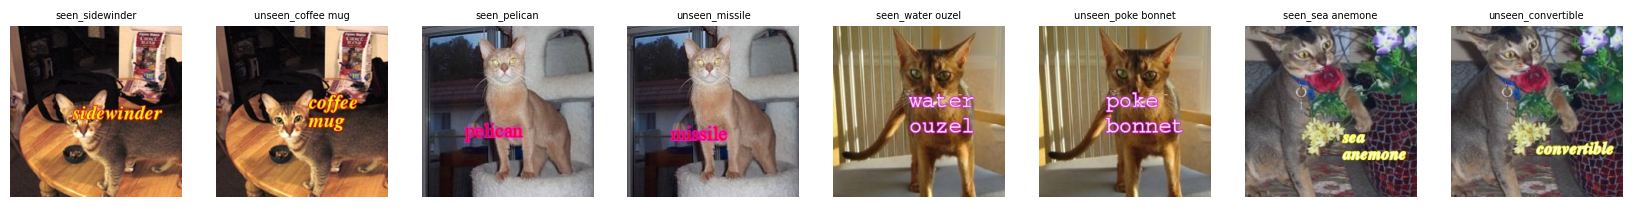

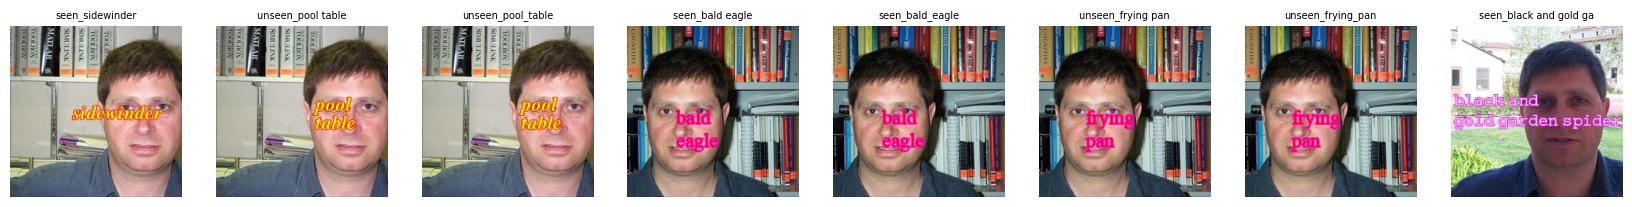

In [8]:
# B3) Look at example pairs (seen word left, unseen word right)
import matplotlib.pyplot as plt
from PIL import Image
for ds in ["pets", "caltech"]:
    ex = sorted(glob.glob(f"{W}/cache_su/examples_{ds}/*.png"))[:8]
    if not ex: continue
    fig, axs = plt.subplots(1, len(ex), figsize=(2.6 * len(ex), 3))
    for ax, f in zip(axs, ex):
        ax.imshow(Image.open(f)); ax.axis("off"); ax.set_title(os.path.basename(f)[4:-4][:22], fontsize=7)
    plt.show()

In [9]:
# B4) Evaluate CLIP and the authors' token on seen / unseen
SU = " ".join(sorted(glob.glob(f"{W}/cache_su/su_*.pt")))
!python eval_seen_unseen.py --data {SU} --tokens authors=learned_token/dp_vit-b32.pt --out {W}/results/seen_unseen_authors

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
{"dataset": "caltech", "model": "clip", "n": 8677, "acc_clean": 81.15, "acc_seen": 58.57, "acc_unseen": 53.76, "hit_seen": 19.57, "hit_unseen": 29.13, "gap_seen_minus_unseen": 4.81, "gap_ci95": [3.77, 5.84]}
{"dataset": "caltech", "model": "authors", "n": 8677, "acc_clean": 82.98, "acc_seen": 72.87, "acc_unseen": 69.85, "hit_seen": 4.56, "hit_unseen": 10.31, "gap_seen_minus_unseen": 3.02, "gap_ci95": [2.19, 3.9], "did": -1.79, "did_ci95": [-2.86, -0.68], "rec_seen": 46.94, "rec_unseen": 44.07, "n_fooled_both": 869, "rec_diff_both": 2.99, "rec_diff_both_ci95": [-0.46, 6.56]}
{"dataset": "pets", "model": "clip", "n": 3669, "acc_clean": 77.95, "acc_seen": 52.03, "acc_unseen": 34.31, "hit_seen": 17.55, "hit_unseen": 50.67, "gap_seen_minus_unseen": 17.72, "gap_ci95": [15.89, 19.46]}
{"dataset": "pets", "model": "authors", "

{"dataset": "caltech", "model": "authors", "n_words_seen": 96, "n_words_unseen": 96, "mean_clip_hit_seen": 19.5, "mean_clip_hit_unseen": 29.33, "slope_on_clip_hit": 0.428, "seen_effect_c": -1.66, "seen_effect_ci95": [-3.51, 0.28]}
{"dataset": "pets", "model": "authors", "n_words_seen": 100, "n_words_unseen": 100, "mean_clip_hit_seen": 17.41, "mean_clip_hit_unseen": 50.26, "slope_on_clip_hit": 0.476, "seen_effect_c": 0.16, "seen_effect_ci95": [-2.71, 3.47]}


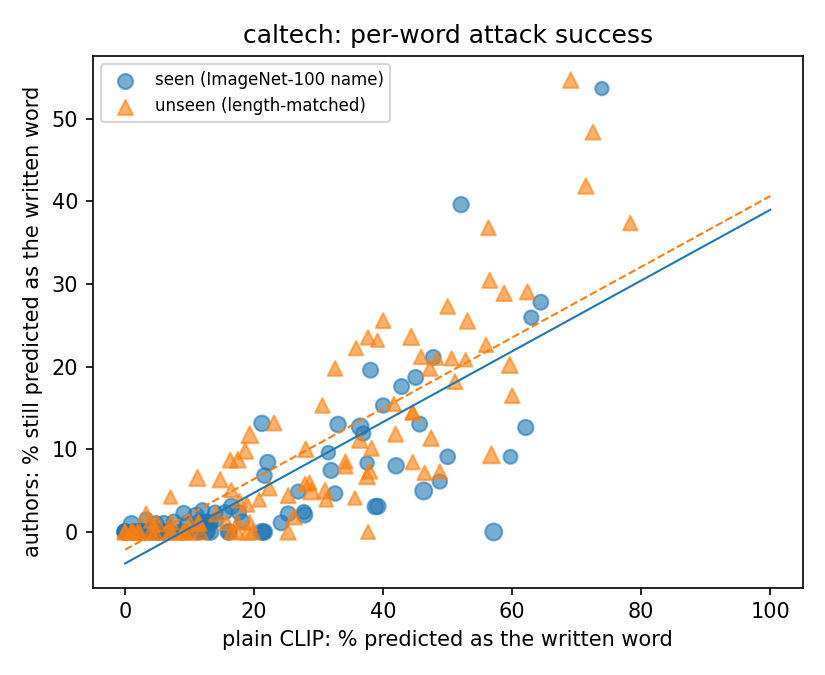

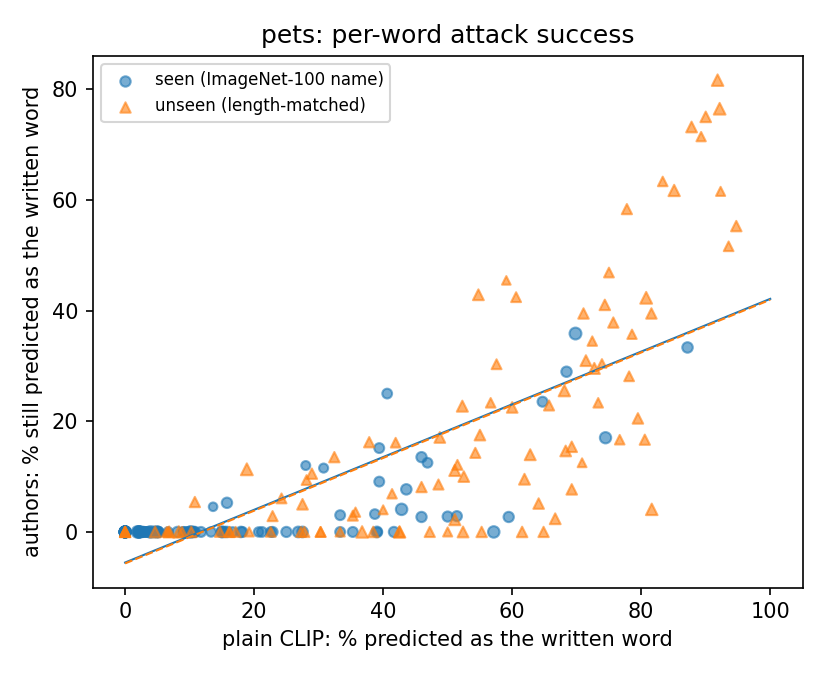

In [10]:
# B5) Word-level control for raw attack strength: at equal plain-CLIP attack success, do seen words get through DP less?
PREDS = " ".join(sorted(glob.glob(f"{W}/results/seen_unseen_authors/preds_*.pt")))
!python analyze_words.py --preds {PREDS} --model authors --out {W}/results/words_authors
from IPython.display import Image as _Img, display
for f in sorted(glob.glob(f"{W}/results/words_authors/*.png")): display(_Img(f, width=480))